# 05 · Perfiles, recompra y decisiones
**Pregunta:** ¿qué significa cada grupo y qué acción comercial merece una prueba?

Se interpretan los segmentos en días, pedidos y GBP. Después se mide qué parte de cada grupo
volvió a comprar en los 90 días reservados, manteniendo el denominador de clientes original.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "config/settings.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Abre el notebook dentro del repositorio.")
    ROOT = ROOT.parent
config = yaml.safe_load((ROOT / "config/settings.yaml").read_text(encoding="utf-8"))
REPORTS = ROOT / "reports"

,segment,name,customers,recency_median,frequency_median,monetary_median,customer_share,revenue_share
0,S01,Baja frecuencia distante,2861,192.0,1.0,386.15,0.66,0.179
1,S02,Recurrentes de alto gasto,1474,29.0,6.0,2165.14,0.34,0.821


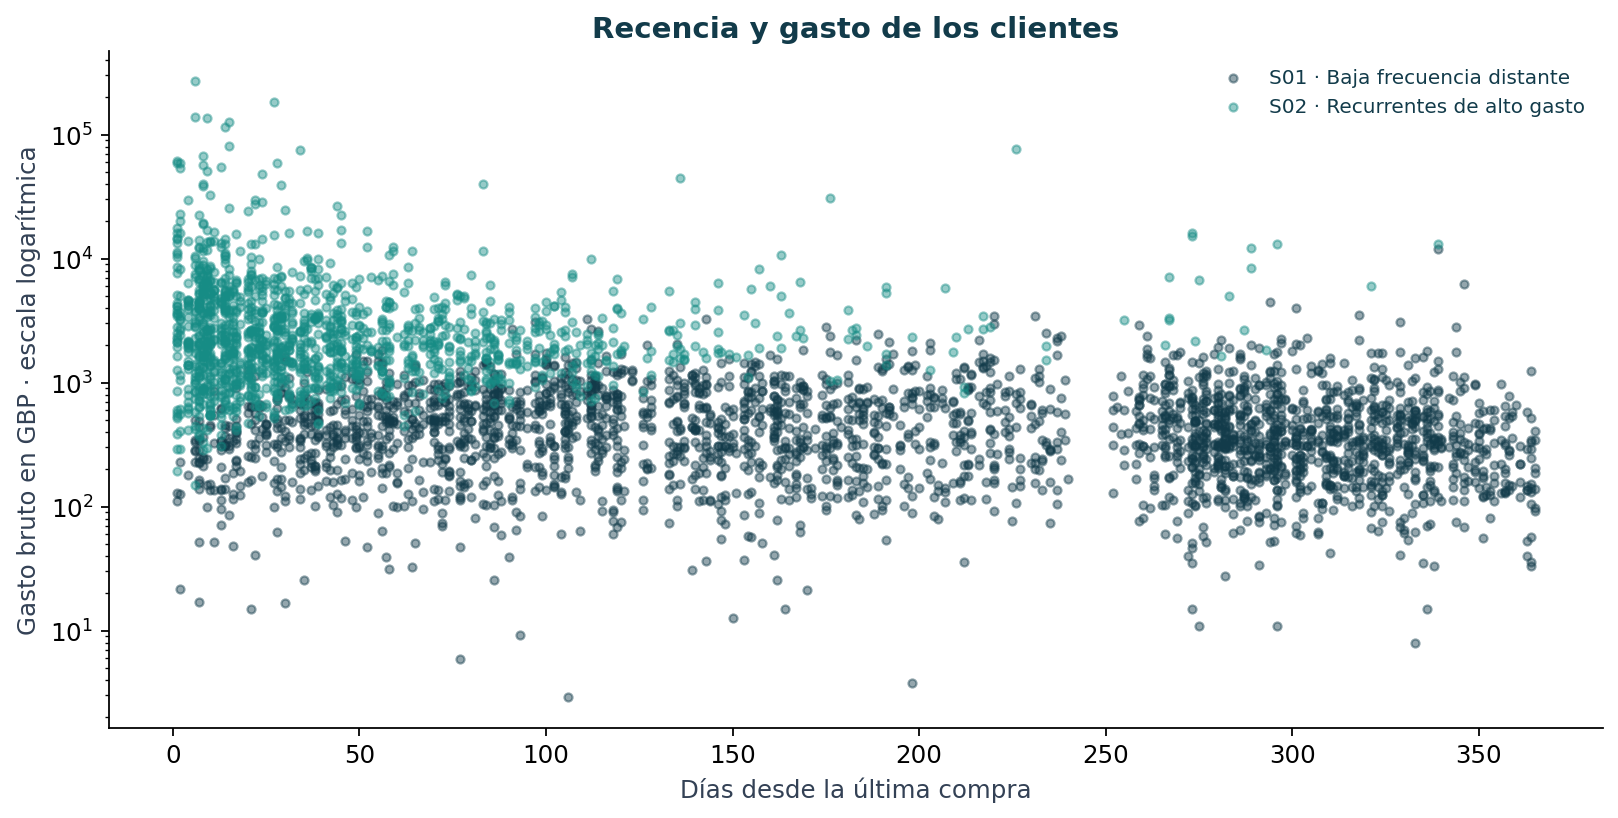

In [2]:
profiles = pd.read_csv(REPORTS / "segment_profiles.csv")
customers = pd.read_csv(ROOT / "data/processed/customer_segments.csv", dtype={"customer_id": str})
display(
    profiles[
        [
            "segment",
            "name",
            "customers",
            "recency_median",
            "frequency_median",
            "monetary_median",
            "customer_share",
            "revenue_share",
        ]
    ].round(3)
)
assert profiles.customers.sum() == len(customers)
assert np.isclose(profiles.revenue_share.sum(), 1)
display(Image(filename=str(REPORTS / "figures/customer_map.png")))

## Comportamiento posterior
La recompra significa al menos una factura positiva posterior. Los clientes sin compras futuras
permanecen con cero. Los nuevos compradores del periodo posterior no se incluyen en los grupos
ya construidos ni cambian sus tasas.

Compradores posteriores nuevos respecto a la foto RFM: 693


,segment,customers,repurchasers,repurchase_rate,future_orders,future_gross_amount,future_amount_per_customer
0,S01,2861,1000,0.350,1559.0,575270.942,201.073
1,S02,1474,1146,0.777,3580.0,2135739.700,1448.941


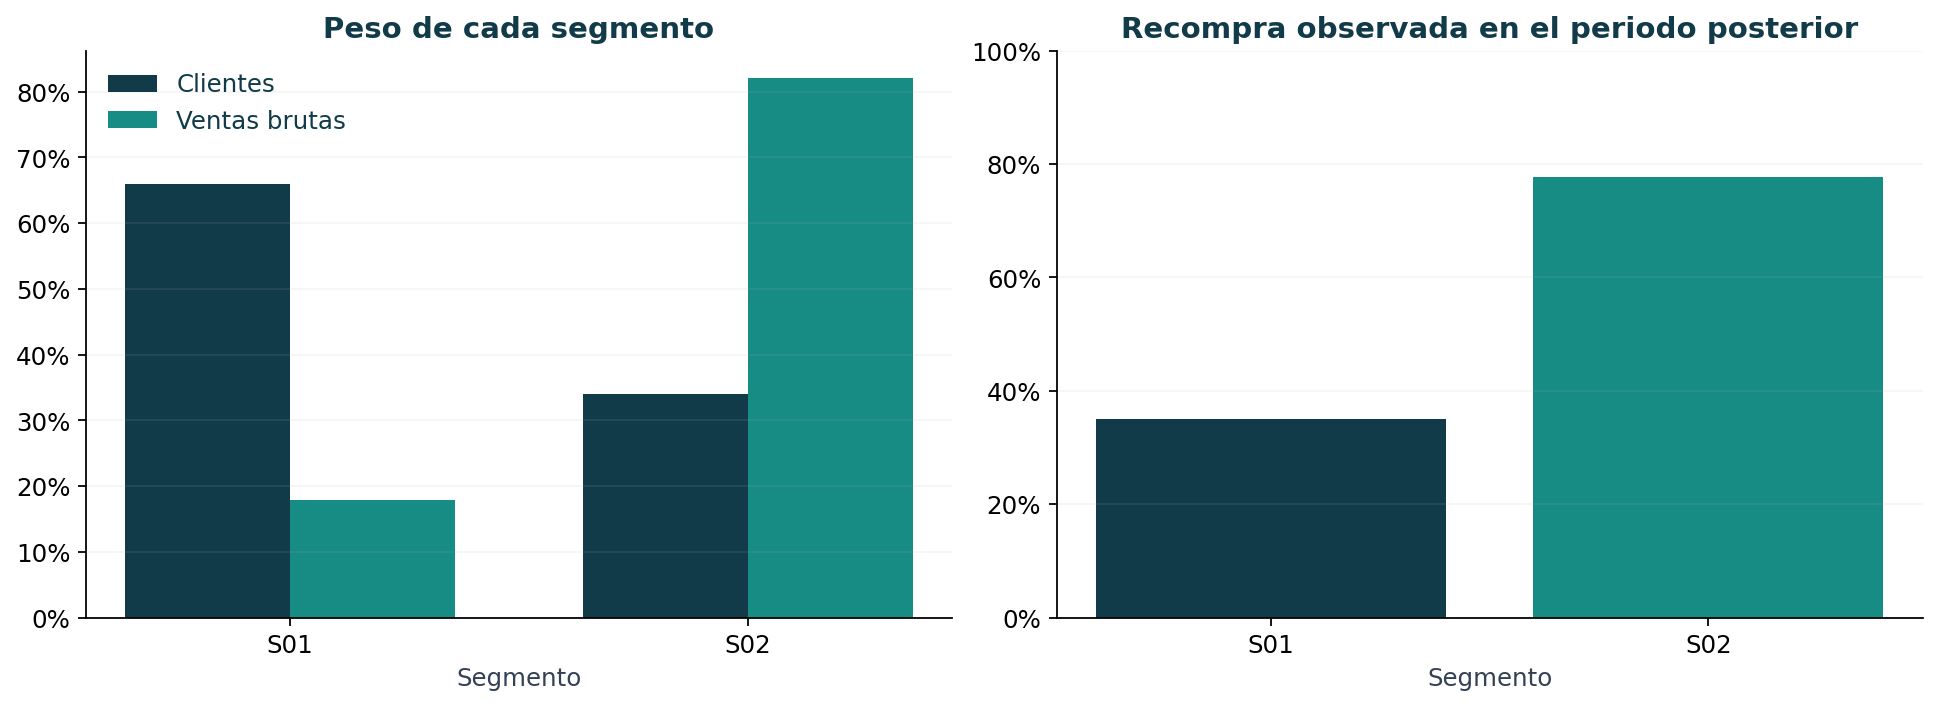

In [3]:
from customer_segmentation.evaluation import evaluate_future
from customer_segmentation.features import future_outcomes

transactions = pd.read_parquet(ROOT / "data/processed/transactions.parquet")
outcomes = future_outcomes(transactions, config["cutoff"], config["evaluation_end"])
temporal = evaluate_future(customers, outcomes)
display(temporal.round(3))
assert temporal.customers.sum() == len(customers)
assert temporal.repurchase_rate.between(0, 1).all()
print(
    "Compradores posteriores nuevos respecto a la foto RFM:",
    (~outcomes.customer_id.isin(customers.customer_id)).sum(),
)
display(Image(filename=str(REPORTS / "figures/segment_overview.png")))

## Acciones comerciales para probar
La diferencia de actividad permite proponer incentivos y beneficios diferentes. Los nombres
se apoyan en medianas: dentro de cada segmento hay variación.

In [4]:
display(profiles[["segment", "name", "proposed_action"]])
print((REPORTS / "executive_summary.md").read_text(encoding="utf-8"))

# Resumen ejecutivo

El 10 % de los clientes con mayor gasto concentra el **60.3% de las ventas brutas**. Conviene probar acciones distintas según la actividad de compra de cada grupo.

Se analizaron **4,335 clientes** y **17,822 pedidos**, con ventas brutas de **£8,279,871.60**. El **63.7%** realizó más de un pedido.

## Perfiles y evidencia

| Segmento | Perfil | Clientes | Ventas brutas | Recompra posterior |
|---|---|---:|---:|---:|
| S01 | Baja frecuencia distante | 2,861 | 17.9% | 35.0% |
| S02 | Recurrentes de alto gasto | 1,474 | 82.1% | 77.7% |

## Decisiones para probar

- **S01:** Probar un incentivo de recompra y medir conversión incremental.
- **S02:** Probar beneficios de fidelización y medir recompra y margen.

## Cómo leer estos resultados

Observación: `2010-09-01` ≤ fecha < `2011-09-01`. Evaluación: `2011-09-01` ≤ fecha < `2011-11-30` (90 días). Se cuenta como recompra al menos un pedido positivo posterior. El denominador incluye todos los clientes del segmento, compr

,segment,name,proposed_action
0,S01,Baja frecuencia distante,Probar un incentivo de recompra y medir conver...
1,S02,Recurrentes de alto gasto,Probar beneficios de fidelización y medir reco...


## Siguiente paso comercial
Para medir impacto se asignarían aleatoriamente clientes a campaña y control dentro de cada
grupo. La comparación incluiría recompra incremental, margen y costo del incentivo. El dataset
no contiene esos costos ni campañas ejecutadas, por lo que no se calcula un ROI ficticio.

Los perfiles son históricos y corresponden a clientes identificados de esta tienda. No equivalen
a una predicción individual de abandono ni describen el mercado actual.

[Volver al resumen del proyecto](../README.md)